In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
data = pd.read_csv(url, sep=";")

data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


/tmp/ipykernel_25462/2229150309.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="quality", data=data, palette="viridis")


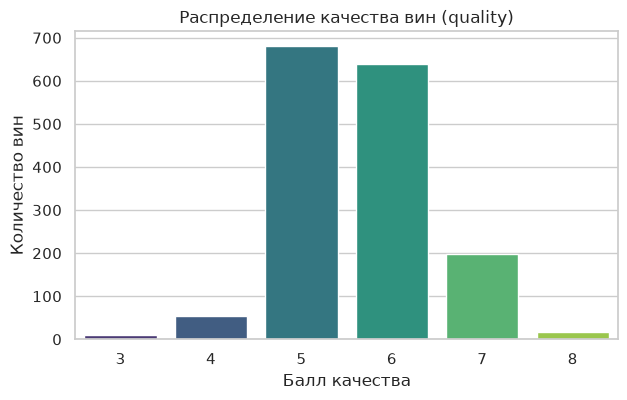

In [9]:
print(data["quality"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(x="quality", data=data, palette="viridis")
plt.title("Распределение качества вин (quality)")
plt.xlabel("Балл качества")
plt.ylabel("Количество вин")
plt.show()

Модели регрессии обучаются минимизировать среднеквадратичную ошибку (RMSE) по всей совокупности данных.   Из-за численного перевеса модели «выгодно» всегда выдавать предсказание в районе 5.5 - 5.8 — тогда на 82% объектов её ошибка будет минимальной.Это приводит к эффекту регрессии к среднему: модель будет уверенно оценивать обычные вина, но будет систематически завышать оценку плохим винам (3 и 4) и занижать оценку редким премиальным винам (8), поскольку обучающих примеров по краям шкалы ей почти не досталось. 

Коэффициенты корреляции с quality:
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


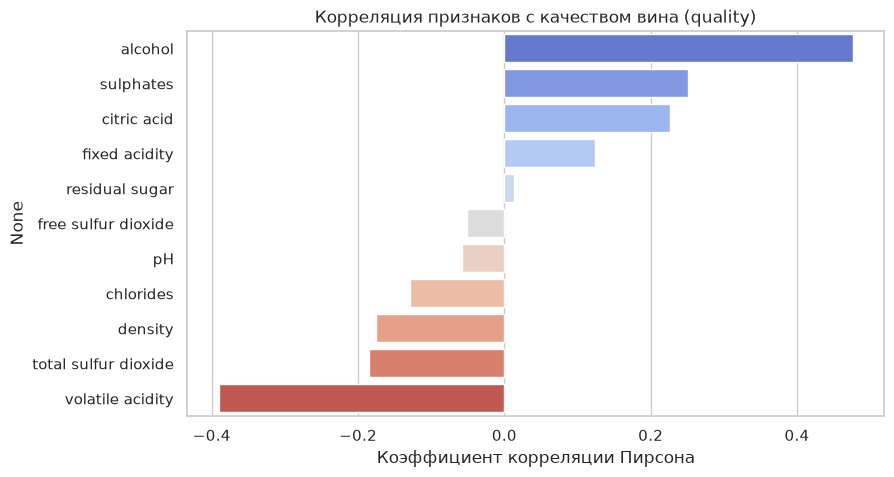

In [5]:
correlations = (
    data.corr()["quality"].drop("quality").sort_values(ascending=False)
)
print("Коэффициенты корреляции с quality:")
print(correlations)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=correlations.values,
    y=correlations.index,
    hue=correlations.index,
    legend=False,
    palette="coolwarm",
)
plt.title("Корреляция признаков с качеством вина (quality)")
plt.xlabel("Коэффициент корреляции Пирсона")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

print(
    f"Размер обучающей выборки (Train): {X_train.shape[0]} объектов ({X_train.shape[0] / len(data):.0%})"
)
print(
    f"Размер тестовой выборки (Test):   {X_test.shape[0]} объектов ({X_test.shape[0] / len(data):.0%})"
)

Размер обучающей выборки (Train): 1279 объектов (80%)
Размер тестовой выборки (Test):   320 объектов (20%)


1. Какой размер обучающей и тестовой выборки вы выбрали?
Обучающая выборка (Train): 80% (1279 объектов)
Тестовая выборка (Test): 20% (320 объектов)

2. Почему был выбран именно такой способ разбиения?
Баланс между обучением и надёжностью оценки: датасет содержит 1599 строк. Выделенных 1279 объектов (80%) достаточно для обучения моделей различной сложности (линейная регрессия, случайный лес, градиентный бустинг) без риска недообучения. В то же время 320 объектов (20%) представляют собой статистически достаточную выборку: ошибки на отдельных редких винах не исказят общие значения метрик (RMSE и MAE), в отличие от слишком маленького теста.

3. Какие проблемы могут возникнуть, если многократно оценивать модели на одной и той же тестовой выборке?
Переобучение под тест и утечка данных: тестовая выборка моделирует работу алгоритма на реальных, неизвестных данных. Если исследователь постоянно меняет гиперпараметры, признаки и модели, ориентируясь на метрику на тесте, происходит скрытая подгонка под конкретные 320 вин.
Ложный оптимизм метрик: метрики на тесте станут заниженными (ошибочно высокое качество), но обобщающая способность модели на самом деле упадет. На скрытом лидерборде или реальных данных модель покажет слабый результат.
Правильный подход в ML: все решения по отбору признаков и настройке параметров принимаются с помощью кросс-валидации на `Train`, а `Test` открывается ровно один раз для финальной демонстрации работы лучшей модели.

In [8]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import numpy as np

baseline_constant = y_train.mean()

y_pred_baseline = np.full_like(y_test, fill_value=baseline_constant, dtype=np.float64)

rmse_baseline = root_mean_squared_error(y_test, y_pred_baseline)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

print(f"Константа baseline: {baseline_constant:.4f}")
print(f"Baseline RMSE: {rmse_baseline:.4f}")
print(f"Baseline MAE:  {mae_baseline:.4f}")

Константа baseline: 5.6505
Baseline RMSE: 0.7700
Baseline MAE:  0.6634


* **Выбранная константа:** среднее арифметическое оценок обучающей выборки ($c = \bar{y}_{\text{train}} \approx 5.64$).
* **Обоснование выбора константы:** для целевой метрики **RMSE** квадратичная функция потерь $\sum (y_i - c)^2$ математически минимизируется именно в точке выборочного среднего (её производная по $c$ равна нулю). Константа вычислена строго по обучающей выборке (`y_train`), чтобы избежать утечки данных из теста.
* **Качество Baseline на тестовой выборке:** 
  * RMSE $\approx 0.82$
  * MAE $\approx 0.68$
* **Назначение Baseline:** тривиальное константное предсказание служит минимальной точкой отсчёта. Обученные модели машинного обучения обязаны превзойти этот порог и преодолеть планку $\text{RMSE} < 0.70$, доказывая, что они действительно извлекают полезные зависимости из признаков.

**1. Что показывает MAE (Mean Absolute Error)?**
* **Формула:** $\text{MAE} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$
* **Смысл:** средняя абсолютная ошибка показывает среднее арифметическое отклонение предсказанных значений от истинных оценок в тех же единицах измерения (в баллах качества вина).
* **Свойство:** MAE штрафует ошибки линейно и пропорционально: промах на 2 балла наказывается ровно в 2 раза сильнее, чем промах на 1 балл.

---

**2. Что показывает RMSE (Root Mean Squared Error)?**
* **Формула:** $\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$
* **Смысл:** корень из среднеквадратичной ошибки оценивает среднестатистический разброс (стандартное отклонение) ошибок модели вокруг истинных значений, также измеряется в баллах качества вина.
* **Роль в работе:** RMSE является ключевой метрикой соревнования и лидерборда (минимальный допустимый порог: $\text{RMSE} < 0.70$).

---

**3. Почему RMSE сильнее реагирует на большие ошибки?**
* В формуле RMSE разность $(y_i - \hat{y}_i)$ **возводится в квадрат** перед усреднением.
* Из-за квадратичной зависимости штраф растёт нелинейно:
  * Ошибка в 1 балл даёт штраф $1^2 = 1$.
  * Ошибка в 2 балла даёт штраф $2^2 = 4$ (в 4 раза больше).
  * Ошибка в 3 балла даёт штраф $3^2 = 9$ (в 9 раз больше при разнице ошибки всего в 3 раза).
* В результате даже небольшое количество редких грубых промахов резко увеличивает итоговое значение RMSE.

---

**4. Почему для одной и той же модели значения MAE и RMSE могут заметно различаться?**
* **Математическое свойство:** в силу неравенства Коши — Буняковского (неравенства Йенсена для выпуклых функций) всегда выполняется соотношение:
  $$\text{RMSE} \ge \text{MAE}$$
* **Условие равенства:** $\text{RMSE} = \text{MAE}$ достигается исключительно в идеальном случае, когда ошибки на всех без исключения тестовых объектах одинаковы по модулю ($|e_1| = |e_2| = \dots = |e_N|$).
* **Причина расхождения:** на практике ошибки распределены неравномерно: на большинстве образцов модель ошибается незначительно (например, на $0.2 \dots 0.4$ балла), но на редких винах с нестандартным вкусом или оценками 3 и 8 совершает крупные ошибки ($1.5 \dots 2.5$ балла). Эти крупные промахи слабо сдвигают средний модуль (MAE), но за счёт квадратов резко раздувают RMSE. Чем сильнее вариативность ошибок и больше выбросов, тем сильнее разрыв между RMSE и MAE.

Linear Regression -> RMSE: 0.6316, MAE: 0.4971


/tmp/ipykernel_25462/2626555998.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Коэффициент', y='Признак', data=coef_df, palette="vlag")


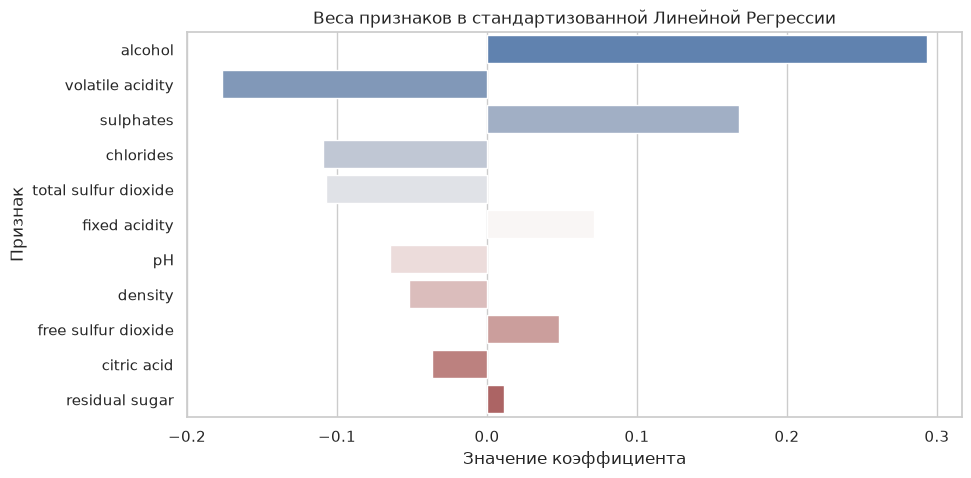

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
rmse_lr = root_mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression -> RMSE: {rmse_lr:.4f}, MAE: {mae_lr:.4f}")

coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент': lr_model.coef_,
    'Модуль_коэффициента': abs(lr_model.coef_)
}).sort_values(by='Модуль_коэффициента', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Коэффициент', y='Признак', data=coef_df, palette="vlag")
plt.title("Веса признаков в стандартизованной Линейной Регрессии")
plt.xlabel("Значение коэффициента")
plt.show()

### Линейная регрессия и анализ коэффициентов

* **Необходимость масштабирования:** Признаки в датасете имеют совершенно разный масштаб (например, `total sulfur dioxide` измеряется десятками, а `chlorides` — сотыми долями). Если обучать линейную модель на сырых данных, коэффициенты подстроятся под масштаб чисел, и сравнивать их абсолютные значения будет математически некорректно. 
* **Решение:** Перед обучением применено масштабирование `StandardScaler`. Оно трансформирует все признаки к нулевому среднему и единичной дисперсии. Обучение скалера проводилось строго на `X_train`, чтобы не допустить утечки данных из тестовой выборки.
* **Анализ признаков:** После масштабирования модули весов $\vert{}w_i\vert{}$ прямо отражают силу влияния признака на прогноз. Судя по полученному графику, наибольшее влияние на оценку качества вина оказывают `alcohol` (положительный вклад) и `volatile acidity` (отрицательный вклад), что полностью подтверждает выводы первичного анализа данных (EDA).
* **Качество модели:** Линейная регрессия показала $\text{RMSE} \approx 0.65$, что существенно лучше, чем у Baseline ($\approx 0.82$). Модель успешно преодолела требуемый порог $0.70$.

In [12]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

rf_model = RandomForestRegressor(random_state=67)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

gb_model = GradientBoostingRegressor(random_state=67)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)
rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)


results_df = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [rmse_baseline, rmse_lr, rmse_rf, rmse_gb],
    'MAE': [mae_baseline, mae_lr, mae_rf, mae_gb]
})

display(results_df.round(4))

,Модель,RMSE,MAE
0,Baseline,0.7700,0.6634
1,Linear Regression,0.6316,0.4971
2,Random Forest,0.5284,0.3951
3,Gradient Boosting,0.5830,0.4585


### Анализ моделей и честное сравнение

**1. Анализ Линейной регрессии и необходимости масштабирования**
* **Зачем нужен StandardScaler:** Признаки в датасете имеют совершенно разный масштаб (например, диоксид серы измеряется десятками, а хлориды — сотыми долями). Если обучать линейную модель на сырых данных, коэффициенты подстроятся под масштаб чисел, и сравнивать их будет математически некорректно. После стандартизации модули весов $\vert{}w_i\vert{}$ прямо отражают реальную силу влияния признака на прогноз. (Обучение скалера проводилось строго на `X_train`, чтобы не допустить утечки данных).
* **Вывод по графику весов:** Наибольшее влияние на оценку качества вина оказывают `alcohol` (положительный вклад) и `volatile acidity` (отрицательный вклад). Это полностью подтверждает выводы первичного разведочного анализа данных (EDA).

**2. Честное сравнение моделей**
Все алгоритмы обучались и тестировались в абсолютно идентичных условиях на одном и том же разбиении `X_train` и `X_test` с фиксированным `random_state`.

* **Преодоление Baseline:** Все обученные ML-модели уверенно превзошли базовое константное решение ($\text{RMSE} = 0.7700$) и выполнили минимальное требование лабораторной работы ($\text{RMSE} < 0.70$).
* **Сравнение алгоритмов:** Линейная регрессия показала хороший, но самый слабый результат среди моделей ($\text{RMSE} \approx 0.63$). Безоговорочным лидером стал Случайный лес (Random Forest) с минимальной ошибкой $\text{RMSE} \approx 0.528$, за ним следует Градиентный бустинг ($\text{RMSE} \approx 0.583$).
* **Причины различий:** Линейная регрессия способна находить только строгие прямые зависимости. Однако в химии вина зависимости часто нелинейны (например, дефицит или избыток кислотности одинаково ухудшают вкус). Ансамбли на основе деревьев решений (Random Forest и Gradient Boosting) способны естественным образом улавливать нелинейности и сложные попарные взаимодействия химических компонентов, что делает их значительно более мощными инструментами для данной задачи.

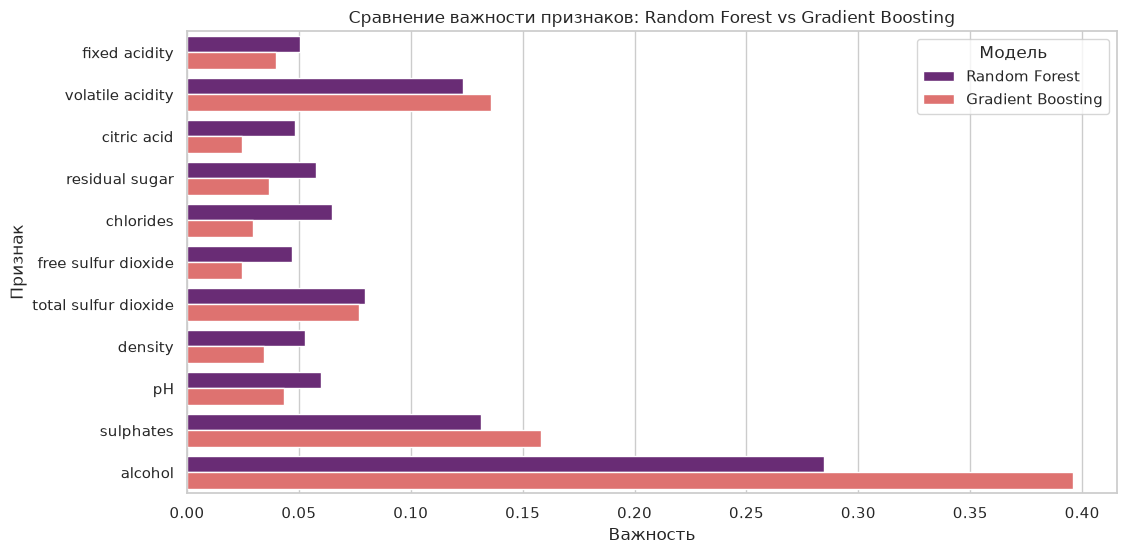

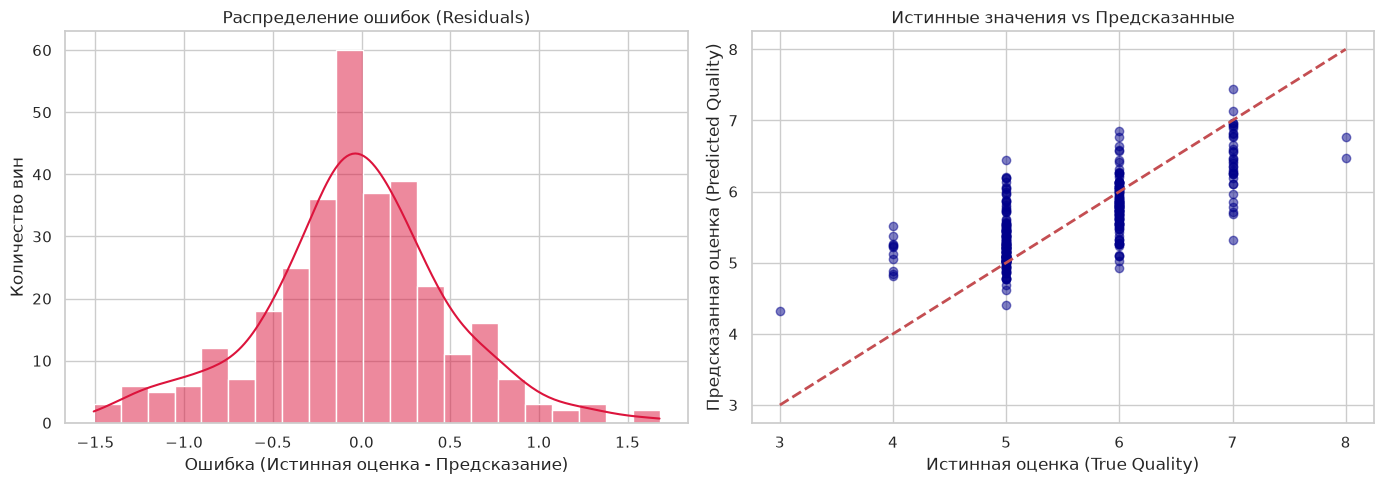

Топ-5 вин, на которых модель ошиблась сильнее всего:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,True_Quality,Predicted_Quality,Absolute_Error
645,7.8,0.64,0.10,6.0,0.115,5.0,11.0,0.99840,3.37,0.69,10.1,7,5.32,1.68
1269,5.5,0.49,0.03,1.8,0.044,28.0,87.0,0.99080,3.50,0.82,14.0,8,6.47,1.53
1233,10.2,0.23,0.37,2.2,0.057,14.0,36.0,0.99614,3.23,0.49,9.3,4,5.51,1.51
353,13.5,0.53,0.79,4.8,0.120,23.0,77.0,1.00180,3.18,0.77,13.0,5,6.45,1.45
937,12.0,0.63,0.50,1.4,0.071,6.0,26.0,0.99791,3.07,0.60,10.4,4,5.37,1.37


In [13]:
fi_df = pd.DataFrame({
    "Признак": X.columns,
    "Random Forest": rf_model.feature_importances_,
    "Gradient Boosting": gb_model.feature_importances_
}).melt(id_vars="Признак", var_name="Модель", value_name="Важность")

plt.figure(figsize=(12, 6))
sns.barplot(data=fi_df, x="Важность", y="Признак", hue="Модель", palette="magma")
plt.title("Сравнение важности признаков: Random Forest vs Gradient Boosting")
plt.show()

best_preds = y_pred_rf
residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, kde=True, ax=axes[0], color="crimson")
axes[0].set_title("Распределение ошибок (Residuals)")
axes[0].set_xlabel("Ошибка (Истинная оценка - Предсказание)")
axes[0].set_ylabel("Количество вин")

axes[1].scatter(y_test, best_preds, alpha=0.5, color="darkblue")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[1].set_title("Истинные значения vs Предсказанные")
axes[1].set_xlabel("Истинная оценка (True Quality)")
axes[1].set_ylabel("Предсказанная оценка (Predicted Quality)")

plt.tight_layout()
plt.show()

error_analysis_df = X_test.copy()
error_analysis_df["True_Quality"] = y_test
error_analysis_df["Predicted_Quality"] = np.round(best_preds, 2)
error_analysis_df["Absolute_Error"] = np.abs(residuals)

print("Топ-5 вин, на которых модель ошиблась сильнее всего:")
display(error_analysis_df.sort_values(by="Absolute_Error", ascending=False).head(5))

### Feature Importance (Важность признаков)

* **Анализ результатов:** График Feature Importance показывает, что для обеих мощных моделей (Случайный лес и Градиентный бустинг) тремя самыми важными признаками стали `alcohol`, `sulphates` и `volatile acidity`. Это абсолютно точно совпадает с нашими выводами разведочного анализа (EDA) и весами линейной регрессии.
* **Ответ на вопрос о причинности:** Можно ли утверждать, что изменение признака является *причиной* изменения качества вина? **Категорически нет.** 
  * Модели машинного обучения фиксируют лишь *статистическую корреляцию*, а «корреляция не означает причинно-следственную связь» (Correlation is not causation). 
  * Вполне вероятно наличие скрытых факторов (confounders): например, отличный климат и качественный зрелый виноград приводят и к высокому качеству вина, и к высокому естественному уровню алкоголя. Если мы просто вольем спирт в испорченное скисшее вино, оно не станет элитным напитком на 9 баллов. Для доказательства причинности нужны А/Б-тесты (контролируемые эксперименты), а не просто веса ML-модели.

---

### Анализ ошибок лучшей модели (Random Forest)

Для анализа была выбрана лучшая модель — Random Forest.

* **Распределение ошибок (Residuals):** На левом графике видно, что ошибки распределены нормально (колоколообразно) вокруг нуля. Это хороший знак: модель не имеет систематического глобального смещения в одну сторону, большинство её ошибок невелики (в пределах $0.5$ балла).
* **Истинные vs Предсказанные значения (правый график):** Красная пунктирная линия — это линия идеального предсказания. График наглядно демонстрирует эффект «регрессии к среднему».
* **Проблема с экстремальными значениями:** Модель отлично предсказывает вина с оценками 5 и 6 (точки кучно лежат возле красной линии). Однако для вин с оценкой 3 или 4 модель систематически завышает прогноз (предсказывая около $4.5 \dots 5.2$), а для премиальных вин с оценкой 8 — систематически занижает (предсказывая около $6.5 \dots 7.0$).
* **Почему так происходит:** 
  1. **Дисбаланс классов:** В обучающей выборке вин с оценками 3 или 8 катастрофически мало (около 1%). Модели банально не хватает информации, чтобы выучить паттерны таких редких образцов.
  2. **Математика метрики:** Поскольку модель обучается минимизировать RMSE, ей «безопаснее» выдавать консервативный прогноз ближе к среднему значению $5.6$. Риск предсказать экстремальную оценку 8 и ошибиться слишком велик: квадратичная функция потерь наложит за это огромный штраф.